In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import nbimporter
from bike_sharing_data import get_bike_sharing

X_train, X_test, y_train, y_test = get_bike_sharing()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (13903, 12)
Testing data: (3476, 12)


In [3]:
from sklearn.ensemble import GradientBoostingRegressor

model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train
model.fit(X_train, y_train.values.ravel())

print("Gradient Boosting Model training completed!")

Gradient Boosting Model training completed!


In [4]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [5]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Evaluation on testing data
mae = mean_absolute_error(y_test, y_test_pred)

mse = mean_squared_error(y_test, y_test_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_test_pred)

print("Gradient Boosting Model Evaluation on Test Data")
print("-----------------------------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Gradient Boosting Model Evaluation on Test Data
-----------------------------------------------
MAE : 47.14865275808877
MSE : 4766.55631144745
RMSE: 69.04025138603893
R2 Score: 0.8494712018485715


In [6]:
train_r2 = r2_score(y_train, y_train_pred)

# Compare training and testing performance
print("\nTraining R2:", train_r2)
print("Testing R2:", r2)


Training R2: 0.8470749389626152
Testing R2: 0.8494712018485715


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

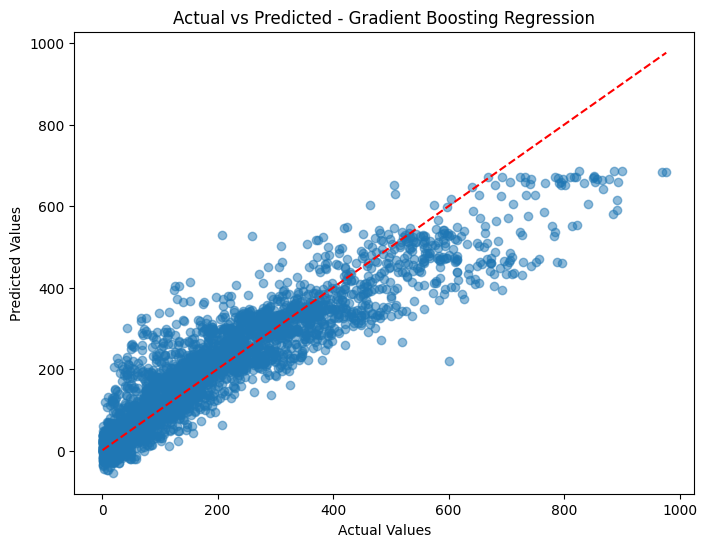

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - Gradient Boosting Regression")

plt.show()

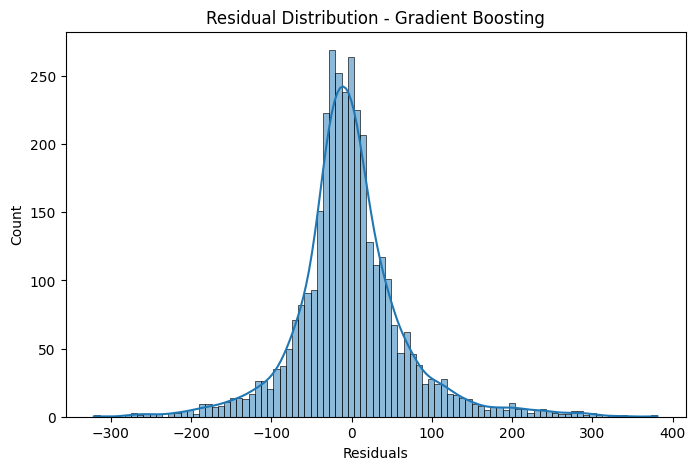

In [9]:
# Residual = Actual value - Predicted value

residuals = np.asarray(y_test).ravel() - y_test_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Residual Distribution - Gradient Boosting")

plt.show()

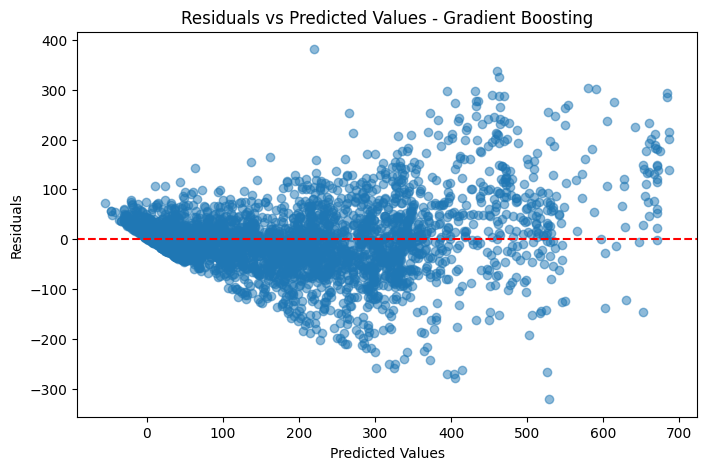

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test_pred, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values - Gradient Boosting")

plt.show()

In [11]:
from bike_sharing_data import bike_sharing_dataset

X, y, _ = bike_sharing_dataset()

X.drop(columns=["dteday"], inplace=True)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
3,hr,0.626849
8,temp,0.093782
1,yr,0.091132
6,workingday,0.080701
9,atemp,0.046199
0,season,0.024797
10,hum,0.012752
7,weathersit,0.012442
2,mnth,0.006244
5,weekday,0.003594


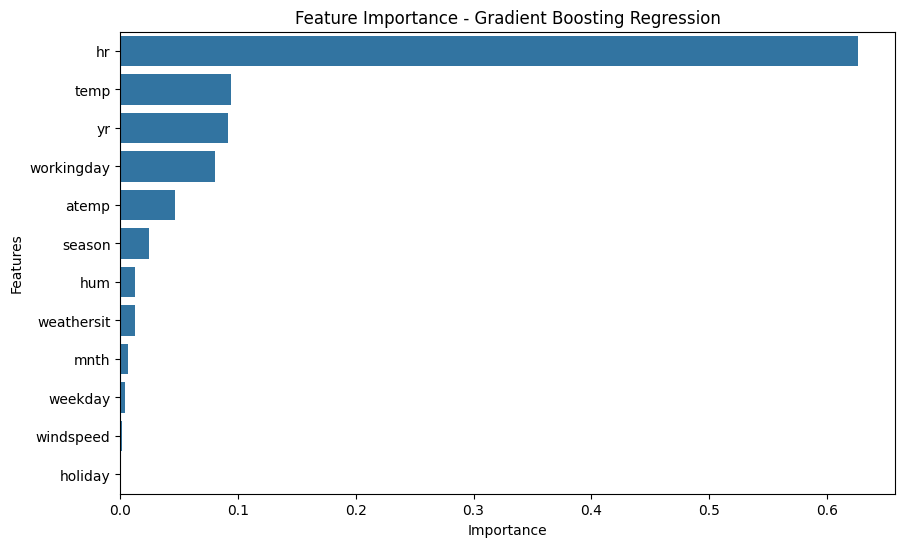

In [12]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance - Gradient Boosting Regression")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()

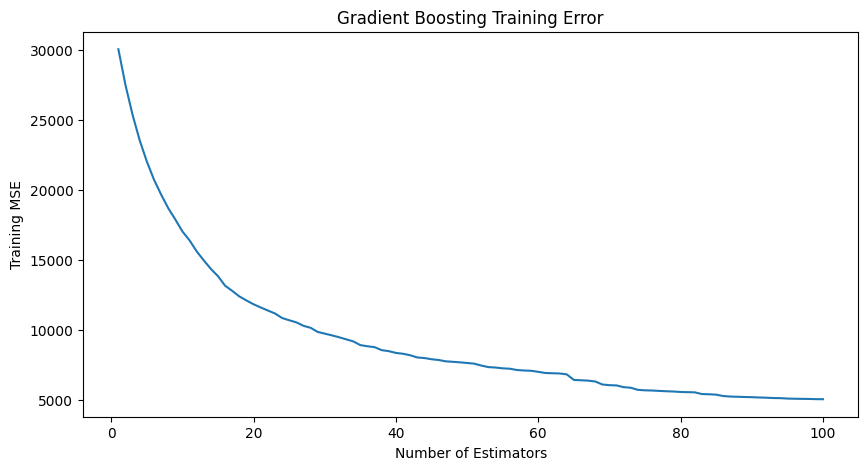

In [13]:
train_errors = []

# Plot: Gradient Boosting training error

for prediction in model.staged_predict(X_train):
    train_errors.append(
        mean_squared_error(y_train, prediction)
    )

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_errors) + 1),
    train_errors
)

plt.xlabel("Number of Estimators")
plt.ylabel("Training MSE")
plt.title("Gradient Boosting Training Error")

plt.show()